# Auswertung stationärer Pumpversuche nach Dupuit-Thiem

**Hydraulische Methoden – Hydrogeologie, KIT**

Dieses Notebook löst die Übungsaufgaben für einen **gespannten** (a) und einen **freien** (b) Grundwasserleiter. Die Eingabewerte sind jeweils in einer eigenen Codezelle zusammengefasst und können für andere Pumpversuche verändert werden.

Wir setzen stationäre, radialsymmetrische Strömung zu einem vollständig verfilterten Brunnen in einem homogenen Grundwasserleiter voraus. Das Verfahren vernachlässigt insbesondere Brunnenverluste und lokale Abweichungen von der Dupuit-Annahme (überwiegend horizontale Strömung).

**Benötigte Pakete:** NumPy und Matplotlib.

## Grundlagen

### Gespannter Grundwasserleiter

Für zwei Beobachtungsbrunnen mit $r_2>r_1$ und $s_1>s_2$ gilt:

$$
Q = 2\pi T\,\frac{s_1-s_2}{\ln(r_2/r_1)},
\qquad T=k_f\,M
$$

Bei mehreren Messstellen kann man die Absenkung $s$ gegen den **logarithmischen Abstand** $\log_{10}(r)$ auftragen und eine Gerade anpassen:

$$s=a+b\,\log_{10}(r)\qquad(b<0).$$

Der Absenkungsunterschied über eine logarithmische Dekade ist $\Delta s=-b$. Damit:

$$
T=\frac{Q\,\ln(10)}{2\pi\,\Delta s},
\qquad k_f=\frac{T}{M}.
$$

Die rechnerisch extrapolierte **Reichweite $R$** entspricht dem Schnittpunkt der Geraden mit $s=0$:

$$
R=10^{-a/b}.
$$

Für eine einzelne Messstelle lässt sich alternativ mit einer bekannten Transmissivität rechnen:

$$R_i=r_i\,\exp\left(\frac{2\pi T s_i}{Q}\right).$$

**Einheiten:** $Q$ in m³/s, $r$, $s$ und $M$ in m, $T$ in m²/s, $k_f$ in m/s.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

# Einheitliche Darstellung der Diagramme
plt.rcParams.update({"figure.figsize": (7, 4.5), "font.size": 11})

## Aufgabe a: Stationärer Pumpversuch im gespannten Grundwasserleiter

**Gegeben:** $Q=9$ l/s, Grundwasserleitermächtigkeit $M=10$ m und vier Messstellen. Gesucht sind die Transmissivität $T$, der Durchlässigkeitsbeiwert $k_f$ und die Reichweite $R$.

In [2]:
# --- Eingabedaten Aufgabe a ---
messstellen = ["M1", "M2", "M3", "M4"]
r = np.array([0.80, 30.0, 90.0, 215.0])  # Abstand [m]
s = np.array([2.24, 1.09, 0.72, 0.25])   # Absenkung [m]
Q_l_s = 9.0                                  # Entnahmerate [l/s]
M = 10.0                                    # Aquifermaechtigkeit [m]

Q = Q_l_s / 1000.0  # Umrechnung in m³/s

assert np.all(r > 0) and np.all(s >= 0), "r muss > 0 und s >= 0 sein."
assert Q > 0 and M > 0, "Q und M muessen positiv sein."
assert len(r) == len(s) == len(messstellen), "Unterschiedliche Anzahl an Messwerten."

print("Messstelle   r [m]   s [m]")
for name, ri, si in zip(messstellen, r, s):
    print(f"{name:>7}   {ri:6.2f}   {si:5.2f}")
print(f"\nQ = {Q:.4f} m³/s; M = {M:.1f} m")

Messstelle   r [m]   s [m]
     M1     0.80    2.24
     M2    30.00    1.09
     M3    90.00    0.72
     M4   215.00    0.25

Q = 0.0090 m³/s; M = 10.0 m


### 1. Geradlinienverfahren: Transmissivität und $k_f$

Mit `np.polyfit` wird eine lineare Regression von $s$ gegen $\log_{10}(r)$ berechnet. Im Diagramm entspricht die negative Steigung $b$ dem Absenkungsunterschied $\Delta s$ pro Dekade. Es werden **zunächst alle vier Messstellen** verwendet.

In [3]:
# Ausgleichsgerade s = a + b * log10(r)
b, a = np.polyfit(np.log10(r), s, 1)

delta_s = -b                   # Absenkungsunterschied pro Dekade [m]
T = Q * np.log(10) / (2 * np.pi * delta_s)
k_f = T / M
R = 10 ** (-a / b)            # Reichweite: Schnittpunkt mit s = 0 [m]

# Guete der linearen Regression im halblogarithmischen Diagramm
s_berechnet = a + b * np.log10(r)
ss_res = np.sum((s - s_berechnet) ** 2)
ss_tot = np.sum((s - np.mean(s)) ** 2)
r_quadrat = 1 - ss_res / ss_tot

print("Lineare Regression mit allen vier Messstellen:")
print(f"  s = {a:.4f} {b:+.4f} * log10(r)")
print(f"  Delta s = {delta_s:.3f} m pro Dekade")
print(f"  T       = {T:.3e} m²/s")
print(f"  k_f     = {k_f:.3e} m/s")
print(f"  R       = {R:.0f} m")
print(f"  R²      = {r_quadrat:.3f}")

Lineare Regression mit allen vier Messstellen:
  s = 2.1964 -0.7915 * log10(r)
  Delta s = 0.792 m pro Dekade
  T       = 4.167e-03 m²/s
  k_f     = 4.167e-04 m/s
  R       = 595 m
  R²      = 0.991


### 2. Grafische Bestimmung der Reichweite

Die Reichweite $R$ wird durch **Extrapolation der Ausgleichsgeraden bis zur Absenkung $s=0$** bestimmt. Dieser Wert ist insbesondere bei gestreuten Messwerten empfindlich gegenüber der Lage der Geraden.

Als Illustration wird zusätzlich eine Gerade durch **M1–M3** angepasst. Sie ist **keine automatische Ausreißerbereinigung**; sie zeigt lediglich, weshalb bei der manuellen grafischen Auswertung andere Reichweiten entstehen können.

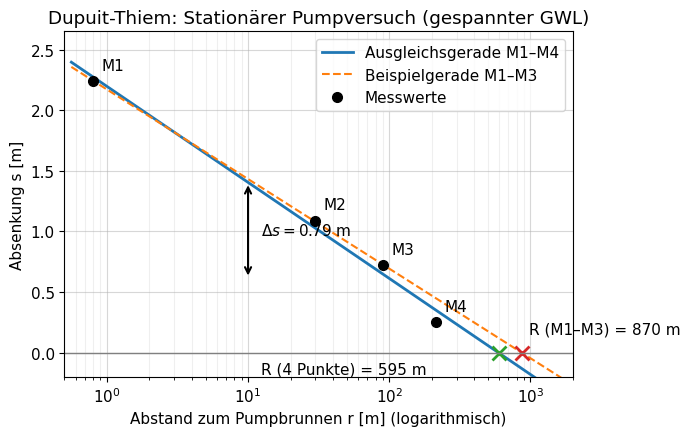

Alle 4 Messstellen: T = 4.167e-03 m²/s, R = 595 m
Nur M1–M3:          T = 4.466e-03 m²/s, R = 870 m


In [4]:
# Alternative, nur zur Veranschaulichung der grafischen Unsicherheit:
# Ausgleichsgerade aus den ersten drei Messstellen
b_123, a_123 = np.polyfit(np.log10(r[:3]), s[:3], 1)
R_123 = 10 ** (-a_123 / b_123)
T_123 = Q * np.log(10) / (2 * np.pi * (-b_123))

r_plot = np.geomspace(min(r) * 0.7, max(2000, R_123 * 1.5), 400)
s_fit = a + b * np.log10(r_plot)
s_fit_123 = a_123 + b_123 * np.log10(r_plot)

fig, ax = plt.subplots()
ax.semilogx(r_plot, s_fit, label="Ausgleichsgerade M1–M4", linewidth=2)
ax.semilogx(r_plot, s_fit_123, linestyle="--", label="Beispielgerade M1–M3")
ax.semilogx(r, s, "ko", markersize=7, label="Messwerte")

for name, ri, si in zip(messstellen, r, s):
    ax.annotate(name, (ri, si), xytext=(6, 8), textcoords="offset points")

# Die beiden extrapolierten Schnittpunkte mit s = 0 markieren
ax.plot(R, 0, marker="x", markersize=10, markeredgewidth=2)
ax.plot(R_123, 0, marker="x", markersize=10, markeredgewidth=2)
ax.annotate(f"R (4 Punkte) = {R:.0f} m", (R, 0), xytext=(-52, -15),
            textcoords="offset points", ha="right")
ax.annotate(f"R (M1–M3) = {R_123:.0f} m", (R_123, 0), xytext=(5, 14),
            textcoords="offset points")

# Delta s fuer genau eine logarithmische Dekade (10 m -> 100 m)
x_decade = 10.0
s_oben = a + b * np.log10(x_decade)
s_unten = a + b * np.log10(10 * x_decade)
ax.annotate("", xy=(x_decade, s_oben), xytext=(x_decade, s_unten),
            arrowprops={"arrowstyle": "<->", "lw": 1.5})
ax.annotate(rf"$\Delta s = {delta_s:.2f}$ m", (x_decade, (s_oben+s_unten)/2),
            xytext=(9, 0), textcoords="offset points", va="center")

ax.axhline(0, color="gray", linewidth=1)
ax.set(xlabel="Abstand zum Pumpbrunnen r [m] (logarithmisch)",
       ylabel="Absenkung s [m]",
       title="Dupuit-Thiem: Stationärer Pumpversuch (gespannter GWL)")
ax.set_xlim(0.5, max(2000, R_123 * 1.5))
ax.set_ylim(-0.20, 2.65)
ax.grid(True, which="major", alpha=0.5)
ax.grid(True, which="minor", alpha=0.2)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

print(f"Alle 4 Messstellen: T = {T:.3e} m²/s, R = {R:.0f} m")
print(f"Nur M1–M3:          T = {T_123:.3e} m²/s, R = {R_123:.0f} m")

### 3. Rechnerische Reichweite für jede Messstelle

Mit dem zuvor ermittelten $T$ kann für jede Messstelle einzeln $R_i$ berechnet werden. Die Unterschiede zeigen die Unsicherheit dieser extrapolierten Größe. Zusätzlich wird der Zahlenwert aus dem Übungsblatt für M1 mit dem gerundeten $T=4\cdot10^{-3}$ m²/s nachvollzogen.

In [5]:
# Einzelreichweiten mit der Transmissivitaet aus der Regression (M1–M4)
R_einzeln = r * np.exp(2 * np.pi * T * s / Q)

print("Rechnerische Reichweiten mit T aus der Regression:")
for name, Ri in zip(messstellen, R_einzeln):
    print(f"  {name}: R = {Ri:6.1f} m")
print(f"  Arithmetischer Mittelwert: {R_einzeln.mean():.1f} m")
print(f"  Reichweite der Regressionsgeraden: {R:.1f} m")

T_gerundet = 4.0e-3  # Gerundete Musterloesung
R_M1 = r[0] * np.exp(2 * np.pi * T_gerundet * s[0] / Q)
print(f"\nMit T = 4.0e-3 m²/s aus der Musterloesung: R(M1) = {R_M1:.0f} m")

Rechnerische Reichweiten mit T aus der Regression:
  M1: R =  540.8 m
  M2: R =  714.8 m
  M3: R =  730.9 m
  M4: R =  444.9 m
  Arithmetischer Mittelwert: 607.9 m
  Reichweite der Regressionsgeraden: 595.5 m

Mit T = 4.0e-3 m²/s aus der Musterloesung: R(M1) = 417 m


**Vergleich mit der Musterlösung (Aufgabe a):** Dort werden $T\approx4\cdot10^{-3}$ m²/s und $k_f\approx4\cdot10^{-4}$ m/s angegeben. Diese Werte stimmen gut mit der Regression überein.

Für $R$ nennt das Übungsblatt grafisch etwa **700–900 m** sowie rechnerisch für M1 etwa **419 m**. Die Gerade aus M1–M3 liefert hier ungefähr **870 m**, während die lineare Regression aus **allen vier Messstellen rund 595 m** ergibt. Der Unterschied ist kein Rechenfehler, sondern veranschaulicht, wie empfindlich die Extrapolation zum Absenkungsnullpunkt auf die Wahl der Ausgleichsgeraden reagiert. Der Wert ist deshalb nur eine **modellabhängige Näherung** der Reichweite.

## Aufgabe b: Stationärer Pumpversuch im freien Grundwasserleiter

Aus der Abbildung der Übungsaufgabe werden die Größen abgelesen:

- $Q=3$ l/s, $r_1=5$ m, $r_2=25$ m
- $h_1=11$ m, $h_2=12$ m (Wasserstände über der undurchlässigen Basis)
- $H=14$ m (ursprüngliche gesättigte Mächtigkeit; für die direkte Gleichung nicht erforderlich)

Die Dupuit-Thiem-Gleichung für einen **freien** Grundwasserleiter lautet:

$$Q=\pi k_f\,\frac{h_2^2-h_1^2}{\ln(r_2/r_1)}$$

und aufgelöst nach der Durchlässigkeit:

$$k_f=\frac{Q\,\ln(r_2/r_1)}{\pi\,(h_2^2-h_1^2)}.$$

In [6]:
# --- Eingabedaten Aufgabe b ---
Q_b_l_s = 3.0   # [l/s]
r1 = 5.0       # [m]
r2 = 25.0      # [m]
h1 = 11.0      # [m]
h2 = 12.0      # [m]
H = 14.0       # [m], fuer die optionale Kontrolle mit korrigierter Absenkung

Q_b = Q_b_l_s / 1000.0
assert 0 < r1 < r2 and 0 < h1 < h2 <= H and Q_b > 0

kf_frei = Q_b * np.log(r2 / r1) / (np.pi * (h2**2 - h1**2))

print("Stationaerer Pumpversuch im freien Grundwasserleiter:")
print(f"  Q   = {Q_b:.4f} m³/s")
print(f"  r1  = {r1:.1f} m, r2 = {r2:.1f} m")
print(f"  h1  = {h1:.1f} m, h2 = {h2:.1f} m")
print(f"  k_f = {kf_frei:.3e} m/s")

Stationaerer Pumpversuch im freien Grundwasserleiter:
  Q   = 0.0030 m³/s
  r1  = 5.0 m, r2 = 25.0 m
  h1  = 11.0 m, h2 = 12.0 m
  k_f = 6.682e-05 m/s


### Optional: Kontrolle mit korrigierten Absenkungen

Wie im Übungsblatt angegeben, kann für freie Grundwasserleiter aus der gemessenen Absenkung $s=H-h$ eine **korrigierte Absenkung** $s'$ berechnet werden:

$$s'=s-\frac{s^2}{2H}.$$

Damit ergibt sich dieselbe Form wie beim gespannten Grundwasserleiter:

$$Q=2\pi H k_f\,\frac{s'_1-s'_2}{\ln(r_2/r_1)}.$$

Die beiden Berechnungswege müssen zum gleichen $k_f$ führen.

In [7]:
s1 = H - h1
s2 = H - h2
s1_korr = s1 - s1**2 / (2 * H)
s2_korr = s2 - s2**2 / (2 * H)

kf_korr = Q_b * np.log(r2 / r1) / (2 * np.pi * H * (s1_korr - s2_korr))

print(f"Gemessene Absenkungen:  s1 = {s1:.3f} m, s2 = {s2:.3f} m")
print(f"Korrigierte Absenkungen: s1' = {s1_korr:.3f} m, s2' = {s2_korr:.3f} m")
print(f"k_f (direkte Gleichung) = {kf_frei:.6e} m/s")
print(f"k_f (korrigiert)        = {kf_korr:.6e} m/s")

# Beide Formeln sind algebraisch aequivalent.
assert np.isclose(kf_frei, kf_korr)

Gemessene Absenkungen:  s1 = 3.000 m, s2 = 2.000 m
Korrigierte Absenkungen: s1' = 2.679 m, s2' = 1.857 m
k_f (direkte Gleichung) = 6.682174e-05 m/s
k_f (korrigiert)        = 6.682174e-05 m/s


### Darstellung der Absenkungen

Mit zwei Messstellen kann eine halblogarithmische Gerade gezeichnet werden. Zum Vergleich werden die gemessenen und die korrigierten Absenkungen dargestellt. Da nur zwei Messstellen vorhanden sind, beschreibt die Gerade hier keine statistische Regression mit unabhängiger Kontrolle der Linearität.

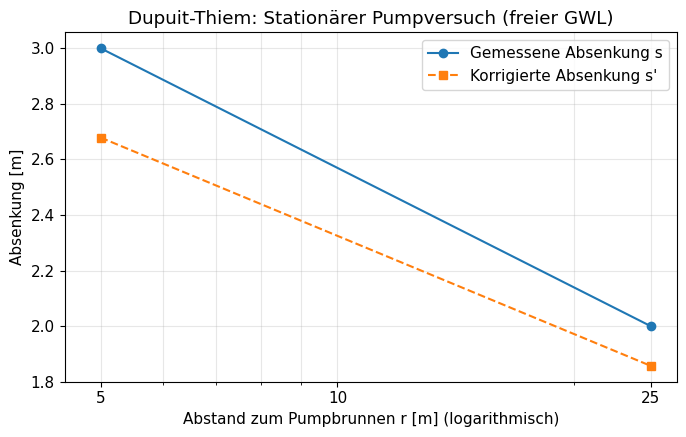

In [8]:
r_b = np.array([r1, r2])
s_b = np.array([s1, s2])
s_b_korr = np.array([s1_korr, s2_korr])

fig, ax = plt.subplots()
ax.semilogx(r_b, s_b, "o-", label="Gemessene Absenkung s")
ax.semilogx(r_b, s_b_korr, "s--", label="Korrigierte Absenkung s'")
ax.set(xlabel="Abstand zum Pumpbrunnen r [m] (logarithmisch)",
       ylabel="Absenkung [m]",
       title="Dupuit-Thiem: Stationärer Pumpversuch (freier GWL)")
from matplotlib.ticker import FixedLocator, FixedFormatter, NullFormatter
ax.xaxis.set_major_locator(FixedLocator([5, 10, 25]))
ax.xaxis.set_major_formatter(FixedFormatter(["5", "10", "25"]))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xlim(4.5, 27)
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## Ergebnisse im Überblick

| Aufgabe | Gesuchter Parameter | Ergebnis |
|:--|:--|:--|
| a: gespannter GWL | Transmissivität $T$ (Regression über M1–M4) | $\approx 4{,}17\cdot 10^{-3}$ m²/s |
| a: gespannter GWL | Durchlässigkeit $k_f$ (Regression über M1–M4) | $\approx 4{,}17\cdot 10^{-4}$ m/s |
| a: gespannter GWL | Reichweite $R$ (Regression über M1–M4) | $\approx 595$ m |
| a: gespannter GWL | Reichweite $R$ (Beispielgerade M1–M3) | $\approx 870$ m |
| b: freier GWL | Durchlässigkeit $k_f$ | $\approx 6{,}68\cdot10^{-5}$ m/s |

**Zum Weiterarbeiten:** Um eigene Messreihen auszuwerten, müssen nur die Eingabedaten in den Zellen zu Aufgabe a bzw. b ersetzt und die betreffenden Zellen erneut ausgeführt werden. Für gespannten GWL sind mindestens zwei Messstellen nötig; bei mehr als zwei Messstellen kann eine Regressionsgerade angepasst werden. Die Interpretation setzt jeweils voraus, dass ein stationärer Zustand erreicht wurde.